**Brain Tumor MRI Classification Group Project**

Group 9: Meagan Behrens, Marc Say, Jacob Buono

## Data Preperation
### 1. Setup and Libraries

Import required libraries and download the Brain Tumor MRI Dataset from Kaggle

In [ ]:
# Import General Libraries
import os
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import tensorflow as tf

# Image Preprocessing
from PIL import Image
from collections import Counter

In [ ]:
# Set Seed
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

tf.config.experimental.enable_op_determinism()

In [ ]:
# Load the Dataset from Kaggle
import kagglehub

path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Path to dataset files: /kaggle/input/brain-tumor-mri-dataset


### 2. Dataset Stucture

The dataset is organized into separate training and testing folders. Each folder contains four subdirectories corresponding to the four classification categories. Check the class distribution of the training and test images in each class and verify the dataset is balanced.

In [ ]:
# Define Dataset Stucture
train_dir = os.path.join(path, "Training")
test_dir = os.path.join(path, "Testing")

classes = ["glioma", "meningioma", "notumor", "pituitary"]

print("Training classes:", os.listdir(train_dir))
print("Testing classes:", os.listdir(test_dir))

Training classes: ['pituitary', 'notumor', 'meningioma', 'glioma']
Testing classes: ['pituitary', 'notumor', 'meningioma', 'glioma']


In [ ]:
# Class Distribution
for class_name in classes:

    train_count = len(os.listdir(os.path.join(train_dir, class_name)))
    test_count = len(os.listdir(os.path.join(test_dir, class_name)))

    print(f"{class_name}: Training = {train_count}, Testing = {test_count}")

glioma: Training = 1400, Testing = 400
meningioma: Training = 1400, Testing = 400
notumor: Training = 1400, Testing = 400
pituitary: Training = 1400, Testing = 400


### 3. Sample MRI Image

Display one representation of each classifcation category, used in final report introduction.

In [ ]:
# Find the highest-resolution image in a class folder
def get_highest_resolution_image(class_path):
    best_file = None
    best_area = 0

    for file_name in os.listdir(class_path):
        image_path = os.path.join(class_path, file_name)

        try:
            img = Image.open(image_path)
            width, height = img.size
            area = width * height

            if area > best_area:
                best_area = area
                best_file = file_name

        except Exception:
            pass

    return best_file

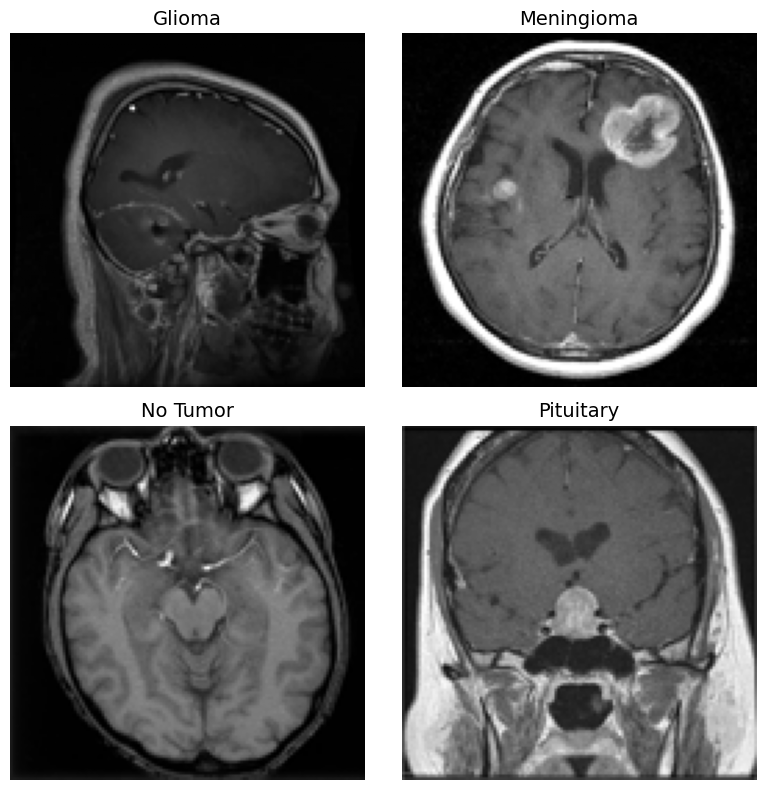

In [ ]:
# Sample MRI Images
display_names = {
    "glioma": "Glioma",
    "meningioma": "Meningioma",
    "notumor": "No Tumor",
    "pituitary": "Pituitary"}

fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.flatten()

for i, class_name in enumerate(classes):

    class_path = os.path.join(train_dir, class_name)
    image_name = get_highest_resolution_image(class_path)
    image_path = os.path.join(class_path, image_name)
    img = Image.open(image_path)
    img = img.resize((128,128))

    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(display_names[class_name], fontsize=14)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

### 4. Image Preprocessing

Convert images to grayscale, resize to 128 x 128 pixels, and normalized pixel values to 0-1. Assign numerical values to the four MRI classification categories.

In [ ]:
# Image Preprocessing
import numpy as np
from PIL import Image

IMG_SIZE = 160

def preprocess_image(image_path):
    img = Image.open(image_path)

    # Convert all images to grayscale
    img = img.convert("L")

    # Resize all images to the same dimensions
    img = img.resize((IMG_SIZE, IMG_SIZE))

    # Convert image to numerical array
    img = np.array(img, dtype=np.float32)

    # Normalize pixel values from 0-255 to 0-1
    img = img / 255.0

    return img

In [ ]:
# Assign Numerical Label to the four Classes
class_labels = {
    "glioma": 0,
    "meningioma": 1,
    "notumor": 2,
    "pituitary": 3}

### 5. Prepare Dataset for Modeling

Preprocess all training and testing images and convert them into NumPy arrays.

In [ ]:
# Load and Preprocess All Images
from tqdm.auto import tqdm

def load_dataset(data_dir):

    images = []
    labels = []

    for class_name in classes:

        class_path = os.path.join(data_dir, class_name)

        # Process every image within the current class
        for file_name in tqdm(
            os.listdir(class_path),
            desc=f"Loading {class_name}"
        ):

            image_path = os.path.join(class_path, file_name)

            try:
                # Apply the preprocessing steps
                img = preprocess_image(image_path)

                # Store the processed image
                images.append(img)

                # Store its corresponding numerical class label
                labels.append(class_labels[class_name])

            except Exception as e:
                print(f"Error loading {image_path}: {e}")

    # Convert lists into NumPy arrays for modeling
    X = np.array(images, dtype=np.float32)
    y = np.array(labels, dtype=np.int32)

    return X, y

### 6. Train, Validation, and Test Split

Create a stratified validation set from the training data while preserving the original testing for final evalutation.

In [ ]:
# Load Training and Testing
X_train_full, y_train_full = load_dataset(train_dir)
X_test, y_test = load_dataset(test_dir)

Loading glioma:   0%|          | 0/1400 [00:00<?, ?it/s]

Loading meningioma:   0%|          | 0/1400 [00:00<?, ?it/s]

Loading notumor:   0%|          | 0/1400 [00:00<?, ?it/s]

Loading pituitary:   0%|          | 0/1400 [00:00<?, ?it/s]

Loading glioma:   0%|          | 0/400 [00:00<?, ?it/s]

Loading meningioma:   0%|          | 0/400 [00:00<?, ?it/s]

Loading notumor:   0%|          | 0/400 [00:00<?, ?it/s]

Loading pituitary:   0%|          | 0/400 [00:00<?, ?it/s]

In [ ]:
print("Training images:", X_train_full.shape)
print("Training labels:", y_train_full.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (5600, 160, 160)
Training labels: (5600,)
Testing images: (1600, 160, 160)
Testing labels: (1600,)


In [ ]:
# Create Validation Set
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full)

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Testing set:", X_test.shape, y_test.shape)

Training set: (4480, 160, 160) (4480,)
Validation set: (1120, 160, 160) (1120,)
Testing set: (1600, 160, 160) (1600,)


## Model Development

### 1. Convolution Nueral Network (CNN)

In [ ]:
# CNN Libraries
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    RandomRotation,
    RandomZoom,
    RandomTranslation)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay)

In [ ]:
# Add a grayscale channel dimension for CNN input
X_train_cnn = np.expand_dims(X_train, axis=-1)
X_val_cnn = np.expand_dims(X_val, axis=-1)
X_test_cnn = np.expand_dims(X_test, axis=-1)

# Verify CNN input dimensions
print("Training:", X_train_cnn.shape)
print("Validation:", X_val_cnn.shape)
print("Testing:", X_test_cnn.shape)

Training: (4480, 160, 160, 1)
Validation: (1120, 160, 160, 1)
Testing: (1600, 160, 160, 1)


Basic CNN

In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

In [ ]:
tf.keras.utils.set_random_seed(42)

basic_cnn = Sequential([
    Input(shape=(160, 160, 1)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dense(4, activation="softmax")
])

In [ ]:
basic_cnn.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

In [ ]:
basic_history = basic_cnn.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=20,
    batch_size=32)

Epoch 1/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 218s 2s/step - accuracy: 0.7299 - loss: 0.6724 - val_accuracy: 0.8313 - val_loss: 0.4553
Epoch 2/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 260s 2s/step - accuracy: 0.8703 - loss: 0.3556 - val_accuracy: 0.8089 - val_loss: 0.5029
Epoch 3/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 214s 2s/step - accuracy: 0.9138 - loss: 0.2393 - val_accuracy: 0.8464 - val_loss: 0.4231
Epoch 4/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 206s 1s/step - accuracy: 0.9460 - loss: 0.1449 - val_accuracy: 0.9054 - val_loss: 0.2655
Epoch 5/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 262s 1s/step - accuracy: 0.9594 - loss: 0.1131 - val_accuracy: 0.9098 - val_loss: 0.2807
Epoch 6/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 214s 2s/step - accuracy: 0.9748 - loss: 0.0708 - val_accuracy: 0.9062 - val_loss: 0.3398
Epoch 7/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 255s 1s/step - accuracy: 0.9786 - loss: 0.0642 - val_accuracy: 0.9312 - val_loss: 0.2536
Epoch 8/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 215s 2s/step - accuracy: 0.9884 - loss: 0.0297 - val_accu

In [ ]:
basic_val_loss, basic_val_accuracy = basic_cnn.evaluate(X_val_cnn, y_val, verbose=0)

print(f"Basic CNN Validation Accuracy: {basic_val_accuracy:.4f}")
print(f"Basic CNN Validation Loss: {basic_val_loss:.4f}")

Basic CNN Validation Accuracy: 0.9420
Basic CNN Validation Loss: 0.3957


In [ ]:
# Classification Report of Basic CNN (Validation Set)
class_names = [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary"]

basic_val_probabilities = basic_cnn.predict(X_val_cnn, verbose=0)
basic_val_predictions = np.argmax(basic_val_probabilities, axis=1)

print("Basic CNN Validation Set Classification Report\n")

print(classification_report(y_val, basic_val_predictions,
        target_names=class_names, digits=4))

Basic CNN Validation Set Classification Report

              precision    recall  f1-score   support

      Glioma     0.9659    0.9107    0.9375       280
  Meningioma     0.8842    0.9000    0.8920       280
    No Tumor     0.9647    0.9750    0.9698       280
   Pituitary     0.9549    0.9821    0.9683       280

    accuracy                         0.9420      1120
   macro avg     0.9424    0.9420    0.9419      1120
weighted avg     0.9424    0.9420    0.9419      1120



In [ ]:
# Classification Report of Basic CNN (Testing Set)
basic_test_probabilities = basic_cnn.predict(X_test_cnn, verbose=0)
basic_test_predictions = np.argmax(basic_test_probabilities, axis=1)
print("Basic CNN Classification Report\n")

print(classification_report(y_test, basic_test_predictions,
        target_names=class_names, digits=4))

Basic CNN Classification Report

              precision    recall  f1-score   support

      Glioma     0.9058    0.7450    0.8176       400
  Meningioma     0.8756    0.8800    0.8778       400
    No Tumor     0.8351    1.0000    0.9101       400
   Pituitary     0.9641    0.9400    0.9519       400

    accuracy                         0.8912      1600
   macro avg     0.8951    0.8912    0.8893      1600
weighted avg     0.8951    0.8912    0.8893      1600



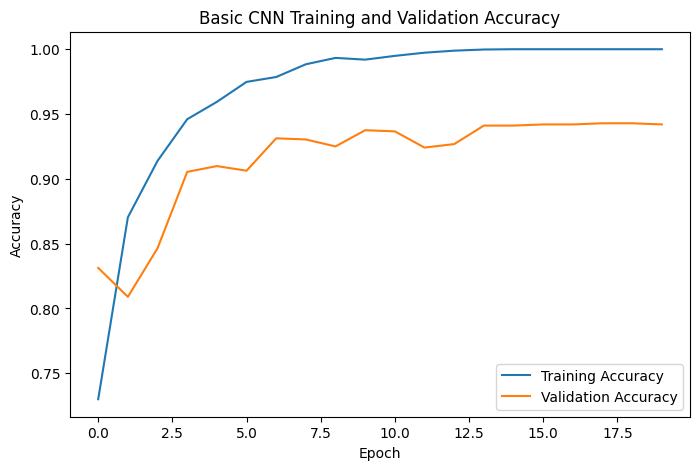

In [ ]:
# Basic CNN Training and Validation Accuracy Plot
plt.figure(figsize=(8, 5))
plt.plot(basic_history.history["accuracy"],
         label="Training Accuracy")

plt.plot(basic_history.history["val_accuracy"],
         label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Basic CNN Training and Validation Accuracy")
plt.legend()
plt.show()

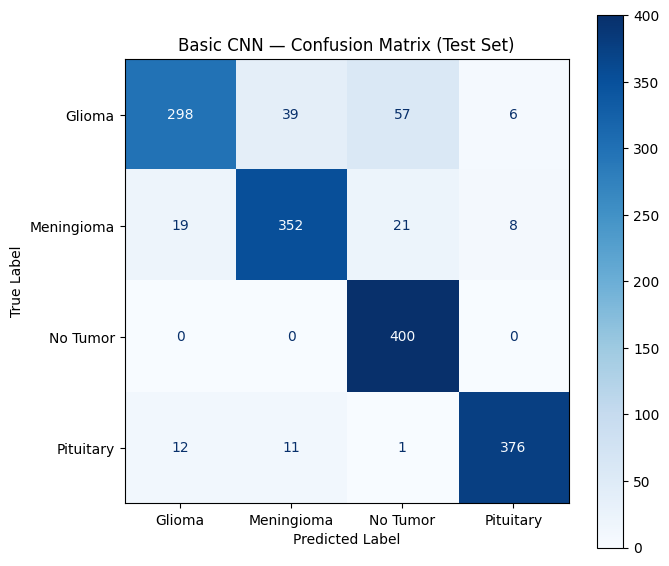

In [ ]:
# Confusion Matrix Basic CNN
basic_test_probabilities = basic_cnn.predict(X_test_cnn,verbose=0)
basic_test_predictions = np.argmax(basic_test_probabilities,axis=1)

cm = confusion_matrix(y_test,basic_test_predictions)

# Display confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_names)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    cmap="Blues",
    ax=ax,
    values_format="d")

plt.title("Basic CNN — Confusion Matrix (Test Set)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

Tuned CNN

Note:

In [ ]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

tuned_cnn = Sequential([
    Input(shape=(160, 160, 1)),

    # Data Augmentation
    RandomRotation(0.015, seed=42),
    RandomZoom(0.03, seed=43),
    RandomTranslation(0.015, 0.015, seed=44),

    # CNN Layers
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dense(4, activation="softmax")
])

In [ ]:
tuned_cnn.compile(
    optimizer= "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

In [ ]:
tuned_cnn_history = tuned_cnn.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=20,
    batch_size=32)

In [ ]:
tuned_val_loss, tuned_val_accuracy = tuned_cnn.evaluate(X_val_cnn, y_val, verbose=0)

print(f"Tuned CNN Validation Accuracy: {tuned_val_accuracy:.4f}")
print(f"Tuned CNN Validation Loss: {tuned_val_loss:.4f}")

In [ ]:
# Classification Report on Validation Set Tuned CNN
tuned_val_probabilities = tuned_cnn.predict(X_val_cnn, verbose=0)
tuned_val_predictions = np.argmax(tuned_val_probabilities,axis=1)

print("Tuned CNN Validation Set Classification Report\n")

print(classification_report(y_val, tuned_val_predictions,
                            target_names=class_names, digits=4))

In [ ]:
# Classification Report on Testing Set Tuned CNN
tuned_test_probabilities = tuned_cnn.predict(X_test_cnn, verbose=0)
tuned_test_predictions = np.argmax(tuned_test_probabilities,axis=1)

print("Tuned CNN Testing Set Classification Report\n")

print(classification_report(y_test, tuned_test_predictions,
                            target_names=class_names, digits=4))

In [ ]:
# Tuned CNN Training and Validation Accuracy Plot
plt.figure(figsize=(8, 5))
plt.plot(tuned_cnn_history.history["accuracy"],
         label="Training Accuracy")

plt.plot(tuned_cnn_history.history["val_accuracy"],
         label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Tuned CNN Training and Validation Accuracy")
plt.legend()
plt.show()

In [ ]:
# Confusion Matrix
tuned_test_probabilities = tuned_cnn.predict(X_test_cnn,verbose=0)
tuned_test_predictions = np.argmax(tuned_test_probabilities,axis=1)

cm = confusion_matrix(y_test,tuned_test_predictions)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    cmap="Blues",
    ax=ax,
    values_format="d")

plt.title("Tuned CNN — Confusion Matrix (Test Set)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

### 2. Support Vector Machine (SVM)

In [ ]:
# Flatten Images and Extract HOG Features for SVM
import time
from skimage.feature import hog
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

class_names = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

# Flatten: each 160 x 160 image becomes one row of raw pixel values
X_train_full_svm = X_train_full.reshape(X_train_full.shape[0], -1)
X_test_svm = X_test.reshape(X_test.shape[0], -1)

# HOG: describes edges and shapes (tumor boundaries) in each 8 x 8 pixel cell
def extract_hog(images):
    return np.array([hog(img, orientations=9, pixels_per_cell=(8, 8),
                         cells_per_block=(2, 2), block_norm="L2-Hys")
                     for img in tqdm(images, desc="Extracting HOG")], dtype=np.float32)

X_train_full_hog = extract_hog(X_train_full)
X_test_hog = extract_hog(X_test)

print("Flattened features:", X_train_full_svm.shape)
print("HOG features:", X_train_full_hog.shape)

In [ ]:
# Baseline to Improved SVM with Stratified 5-Fold Cross-Validation
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

svm_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pca_raw = PCA(n_components=300, svd_solver="randomized", random_state=42)

svm_stages = [
    ("1. Linear SVM (raw pixels)", X_train_full_svm,
        Pipeline([("scale", StandardScaler()),
                  ("svm", SGDClassifier(loss="hinge", alpha=1e-3, max_iter=50, tol=1e-3, random_state=42))])),
    ("2. + PCA", X_train_full_svm,
        Pipeline([("scale", StandardScaler()), ("pca", pca_raw),
                  ("svm", LinearSVC(C=0.01, max_iter=2000))])),
    ("3. + RBF Kernel", X_train_full_svm,
        Pipeline([("scale", StandardScaler()), ("pca", pca_raw), ("svm", SVC(kernel="rbf"))])),
    ("4. + HOG Features", X_train_full_hog,
        Pipeline([("scale", StandardScaler()),
                  ("pca", PCA(n_components=300, svd_solver="randomized", random_state=42)),
                  ("svm", SVC(kernel="rbf"))])),
]

svm_rows = []
for name, X, model in svm_stages:
    start = time.time()
    scores = cross_validate(model, X, y_train_full, cv=svm_cv,
                            scoring=["accuracy", "f1_macro"], n_jobs=-1)
    svm_rows.append({"Stage": name,
                     "CV Accuracy": round(float(scores["test_accuracy"].mean()), 4),
                     "CV Std": round(float(scores["test_accuracy"].std()), 4),
                     "CV Macro F1": round(float(scores["test_f1_macro"].mean()), 4),
                     "Time (s)": round(time.time() - start)})
    print(svm_rows[-1])

svm_results = pd.DataFrame(svm_rows)
svm_results

In [ ]:
# Hyperparameter Tuning: C, gamma, and number of PCA components
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

svm_pipeline = Pipeline([("scale", StandardScaler()),
                         ("pca", PCA(random_state=42)),
                         ("svm", SVC(kernel="rbf"))])

svm_param_dist = {
    "pca__n_components": [100, 150, 200, 300],
    "svm__C": loguniform(0.1, 100),
    "svm__gamma": loguniform(1e-4, 1e-1)}

svm_search = RandomizedSearchCV(svm_pipeline, svm_param_dist, n_iter=15, cv=svm_cv,
                                scoring="accuracy", n_jobs=-1, random_state=42, verbose=1)

start = time.time()
svm_search.fit(X_train_full_hog, y_train_full)
print(f"Search time: {(time.time() - start) / 60:.1f} minutes")

svm_best = svm_search.best_params_
print("\nBest Parameters:")
print(f"  Kernel: RBF")
print(f"  C: {svm_best['svm__C']:.4g}")
print(f"  gamma: {svm_best['svm__gamma']:.4g}")
print(f"  PCA components: {svm_best['pca__n_components']}")
print(f"\nBest CV Accuracy: {svm_search.best_score_:.4f}")

svm_results.loc[len(svm_results)] = {"Stage": "5. + Tuning (C, gamma, PCA)",
                                     "CV Accuracy": round(svm_search.best_score_, 4),
                                     "CV Std": round(svm_search.cv_results_["std_test_score"][svm_search.best_index_], 4),
                                     "CV Macro F1": None, "Time (s)": round(time.time() - start)}
svm_results

In [ ]:
# Evaluate Tuned SVM on the Test Set
svm_final = svm_search.best_estimator_
svm_test_pred = svm_final.predict(X_test_hog)

print("SVM Test Accuracy:", round(accuracy_score(y_test, svm_test_pred), 4))
print()
print(classification_report(y_test, svm_test_pred,
                            target_names=class_names, digits=4))

In [ ]:
# SVM Confusion Matrix
cm = confusion_matrix(y_test, svm_test_pred)

fig, ax = plt.subplots(figsize=(6, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[display_names[c] for c in classes])
disp.plot(ax=ax, cmap="Blues", colorbar=False)

plt.title("SVM Confusion Matrix")
plt.tight_layout()
plt.show()

# False negatives: a real tumor predicted as "No Tumor" (label 2)
false_negatives = np.sum((y_test != 2) & (svm_test_pred == 2))
# False positives: no tumor, but predicted as a tumor
false_positives = np.sum((y_test == 2) & (svm_test_pred != 2))
print(f"False negatives (missed tumors): {false_negatives}")
print(f"False positives (false alarms): {false_positives}")

In [ ]:
# SVM Improvement Plot: Baseline to Tuned
plt.figure(figsize=(8, 5))
bars = plt.bar(svm_results["Stage"].str.split(". ", n=1, regex=False).str[1],
               svm_results["CV Accuracy"], color="#7b6fbf")
plt.bar_label(bars, fmt="%.3f")
plt.ylim(svm_results["CV Accuracy"].min() - 0.1, 1.0)
plt.ylabel("5-Fold CV Accuracy")
plt.title("SVM: Baseline to Tuned")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# SVM Learning Curve (SVMs have no epochs, so this replaces the loss curve)
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    svm_final, X_train_full_hog, y_train_full, cv=svm_cv,
    train_sizes=np.linspace(0.1, 1.0, 6), scoring="accuracy",
    n_jobs=-1, shuffle=True, random_state=42)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_scores.mean(axis=1), "o-", label="Training Accuracy")
plt.plot(train_sizes, val_scores.mean(axis=1), "o-", label="Validation Accuracy")
plt.xlabel("Training Images")
plt.ylabel("Accuracy")
plt.title("SVM Learning Curve")
plt.legend()
plt.tight_layout()
plt.show()

### 3. Random Forest

Flatten Images

In [ ]:
# Flatten Images for Random Forest
X_train_rf = X_train.reshape(X_train.shape[0], -1)
X_val_rf = X_val.reshape(X_val.shape[0], -1)
X_test_rf = X_test.reshape(X_test.shape[0], -1)

# Full training set used for cross-validation
X_train_full_rf = X_train_full.reshape(X_train_full.shape[0], -1)

print("Training set:", X_train_rf.shape)
print("Validation set:", X_val_rf.shape)
print("Testing set:", X_test_rf.shape)
print("Full training set (for cross-validation):", X_train_full_rf.shape)

Basic Random Forest Model

In [ ]:
# Train Basic Random Forest
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_baseline = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1)

start = time.time()
rf_baseline.fit(X_train_rf, y_train)
print(f"Training time: {time.time() - start:.1f} seconds")

val_pred = rf_baseline.predict(X_val_rf)
print("Baseline Validation Accuracy:", round(accuracy_score(y_val, val_pred), 4))

Hyperparameter Tuning with Stratified K-Fold Cross-Validation

In [ ]:
# Hyperparameter Tuning with Stratified K-Fold Cross-Validation
from sklearn.model_selection import StratifiedKFold, GridSearchCV

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

param_grid = {
    "max_depth": [None, 20],
    "max_features": ["sqrt", "log2"],
    "min_samples_leaf": [2, 4],
    "class_weight": [None, "balanced"],
    "max_samples": [0.8, None]}

# Fixed at 50 trees during tuning to keep the search fast
rf_search = GridSearchCV(
    estimator=RandomForestClassifier(
        n_estimators=50,
        random_state=42,
        n_jobs=-1),
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    verbose=2,
    refit=False)

start = time.time()
rf_search.fit(X_train_full_rf, y_train_full)
print(f"Search time: {(time.time() - start) / 60:.1f} minutes")

# Summarize all combinations tried, display the top 10
results_df = pd.DataFrame(rf_search.cv_results_).sort_values("rank_test_score")
results_df[["param_max_depth", "param_max_features", "param_min_samples_leaf",
            "param_class_weight", "param_max_samples",
            "mean_test_score", "std_test_score"]].head(10)

Final Random Forest Model

In [ ]:
# Train Final Random Forest with Best Hyperparameters
best_params = rf_search.best_params_

print("Best Parameters:")
for param, value in best_params.items():
    print(f"  {param}: {value}")
print(f"\nBest CV Accuracy: {rf_search.best_score_:.4f}")

rf_final = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    **best_params)

rf_final.fit(X_train_full_rf, y_train_full)

In [ ]:
# Cross-Validation Score of the Final Model
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    rf_final, X_train_full_rf, y_train_full,
    cv=cv, scoring="accuracy", n_jobs=1)

print("Accuracy per fold:", np.round(cv_scores, 4))
print(f"Mean CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

Evaluation on the Test Set

In [ ]:
# Evaluate Random Forest on the Test Set
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

rf_test_pred = rf_final.predict(X_test_rf)

print("Random Forest Test Accuracy:", round(accuracy_score(y_test, rf_test_pred), 4))
print()
print(classification_report(
    y_test,
    rf_test_pred,
    digits=3,
    target_names=[display_names[c] for c in classes]))

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, rf_test_pred)

fig, ax = plt.subplots(figsize=(6, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[display_names[c] for c in classes])
disp.plot(ax=ax, cmap="Blues", colorbar=False)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

Feature Importance

In [ ]:
# Pixel Feature Importance Map
importances = rf_final.feature_importances_.reshape(IMG_SIZE, IMG_SIZE)

plt.figure(figsize=(6, 6))
plt.imshow(importances, cmap="pink")
plt.colorbar(label="Importance")
plt.title("Random Forest Pixel Importance")
plt.axis("off")
plt.tight_layout()
plt.show()